# P55 — Estymecja przedziałowa
### Sprawozdanie 2, max. 20 pkt.
**Statystyka Matematyczna — Data Science**  

**Imię i nazwisko:** Marcin Zubowski  
**Imię i nazwisko:** Borys Maksymiuk  
**Grupa:** PS2 **Data:** 02.11.2026

**Cel:** Na podstawie rzeczywistych danych z serwisu Kaggle, wykorzystanych we wcześniejszym sprawozdaniu, oszacuj wybrane parametry populacji, porównaj jakość oszacowań i oceń, czy liczebność próby jest wystarczająca. Najważniejsza jest interpretacja statystyczna, nie sposób
wykonania obliczeń. Wykorzystujemy jedną **zmienną ilościową** oraz jedną **cechę zero-jedynkową**.

In [17]:
import numpy as np
import pandas as pd
import scipy.stats as stats
import matplotlib.pyplot as plt
from scipy.stats import normaltest
from IPython.display import display

plik = "USvideos.csv"  # np. dane.csv — plik z folderu notebooka
df = pd.read_csv(plik)   # w razie potrzeby: sep=";", decimal=",", encoding="utf-8"
display(df.head())
print("Wymiary:", df.shape)
print("Kolumny i typy:")
print(df.dtypes)

,video_id,trending_date,title,channel_title,category_id,publish_time,tags,views,likes,dislikes,comment_count,thumbnail_link,comments_disabled,ratings_disabled,video_error_or_removed,description
0,2kyS6SvSYSE,17.14.11,WE WANT TO TALK ABOUT OUR MARRIAGE,CaseyNeistat,22,2017-11-13T17:13:01.000Z,SHANtell martin,748374,57527,2966,15954,https://i.ytimg.com/vi/2kyS6SvSYSE/default.jpg,False,False,False,SHANTELL'S CHANNEL - https://www.youtube.com/s...
1,1ZAPwfrtAFY,17.14.11,The Trump Presidency: Last Week Tonight with J...,LastWeekTonight,24,2017-11-13T07:30:00.000Z,"last week tonight trump presidency|""last week ...",2418783,97185,6146,12703,https://i.ytimg.com/vi/1ZAPwfrtAFY/default.jpg,False,False,False,"One year after the presidential election, John..."
2,5qpjK5DgCt4,17.14.11,"Racist Superman | Rudy Mancuso, King Bach & Le...",Rudy Mancuso,23,2017-11-12T19:05:24.000Z,"racist superman|""rudy""|""mancuso""|""king""|""bach""...",3191434,146033,5339,8181,https://i.ytimg.com/vi/5qpjK5DgCt4/default.jpg,False,False,False,WATCH MY PREVIOUS VIDEO ▶ \n\nSUBSCRIBE ► http...
3,puqaWrEC7tY,17.14.11,Nickelback Lyrics: Real or Fake?,Good Mythical Morning,24,2017-11-13T11:00:04.000Z,"rhett and link|""gmm""|""good mythical morning""|""...",343168,10172,666,2146,https://i.ytimg.com/vi/puqaWrEC7tY/default.jpg,False,False,False,Today we find out if Link is a Nickelback amat...
4,d380meD0W0M,17.14.11,I Dare You: GOING BALD!?,nigahiga,24,2017-11-12T18:01:41.000Z,"ryan|""higa""|""higatv""|""nigahiga""|""i dare you""|""...",2095731,132235,1989,17518,https://i.ytimg.com/vi/d380meD0W0M/default.jpg,False,False,False,I know it's been a while since we did this sho...


Wymiary: (40949, 16)
Kolumny i typy:
video_id                    str
trending_date               str
title                       str
channel_title               str
category_id               int64
publish_time                str
tags                        str
views                     int64
likes                     int64
dislikes                  int64
comment_count             int64
thumbnail_link              str
comments_disabled          bool
ratings_disabled           bool
video_error_or_removed     bool
description                 str
dtype: object


In [15]:
kol_x = "likes"
kol_y = "comments_disabled"

wybrane = df[[kol_x, kol_y]].copy()
wybrane[kol_x] = pd.to_numeric(wybrane[kol_x], errors="coerce")
wybrane[kol_y] = pd.to_numeric(wybrane[kol_y], errors="coerce")
dane = wybrane.dropna()
likes = dane[kol_x].to_numpy()
comments_diabled = dane[kol_y].to_numpy()
print("Przed:", len(df), "Po:", len(dane), "Usunięto:", len(df)-len(dane))
display(dane.head())

Przed: 40949 Po: 40949 Usunięto: 0


,likes,comments_disabled
0,57527,False
1,97185,False
2,146033,False
3,10172,False
4,132235,False


Statystyka testowa: 66944.66
P-value: 0.0
Dane nie pochodzą z rozkładu normalnego


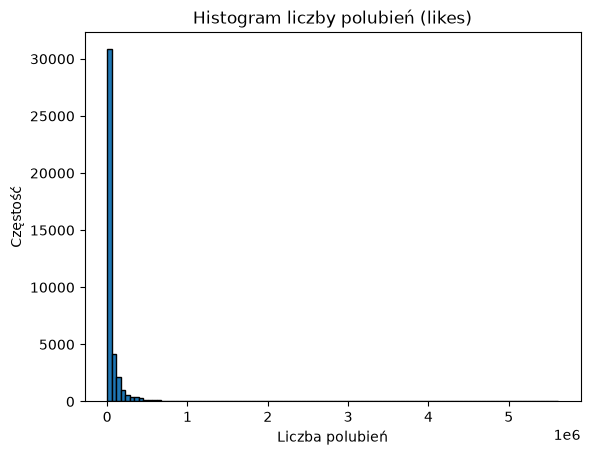

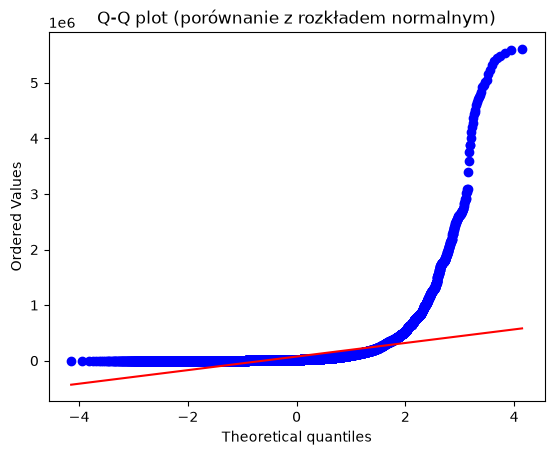

In [20]:
stat, p_value = normaltest(likes)
print(f"Statystyka testowa: {stat:.2f}")
print(f"P-value: {p_value}")
if p_value < 0.05:
    print("Dane nie pochodzą z rozkładu normalnego")

plt.hist(likes, bins=100, edgecolor='black')
plt.title('Histogram liczby polubień (likes)')
plt.xlabel('Liczba polubień')
plt.ylabel('Częstość')
plt.show()

stats.probplot(likes, dist="norm", plot=plt)
plt.title("Q-Q plot (porównanie z rozkładem normalnym)")
plt.show()

In [13]:
n_iterations = 10000
alpha = 0.05

bootstrap_variances = []
for _ in range(n_iterations):
    sample = np.random.choice(likes, size=len(likes), replace=True)
    bootstrap_variances.append(np.var(sample, ddof=1))

lower_bound = np.percentile(bootstrap_variances, (alpha/2) * 100)
upper_bound = np.percentile(bootstrap_variances, (1 - alpha/2) * 100)

print(f"95% przedział ufności bootstrap dla wariancji: [{lower_bound:.2f}, {upper_bound:.2f}]")

95% przedział ufności bootstrap dla wariancji: [45812223677.67, 59408329346.96]
